# <center>**04 - Evaluation**<center>

Notebook này nạp checkpoint medium mới nhất, đánh giá trên tập PrivateTest chưa dùng để huấn luyện, lưu các chỉ số và confusion matrix, sau đó tạo dự đoán cho 500 ảnh đầu tiên trong dữ liệu Kaggle không nhãn.

## **Quy trình trong notebook**

1. Tìm thư mục dự án, chọn CPU/GPU và nạp checkpoint. Cấu hình BatchNorm được suy ra từ các trọng số để tương thích với checkpoint cũ và mới.
2. Tính accuracy, macro-F1 và báo cáo precision/recall/F1 theo từng lớp trên PrivateTest; lưu kết quả vào `exps/`.
3. Vẽ confusion matrix để xem các lớp thường bị nhầm lẫn.
4. Dự đoán 500 ảnh Kaggle và xuất `exps/submission.csv`.

In [5]:
# Imports
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# Project paths and utilities
cwd = Path.cwd().resolve()
ROOT = next(
    path
    for path in (cwd, *cwd.parents)
    if (path / "requirements.txt").exists()
)
sys.path.insert(0, str(ROOT / "src"))

from eval_utils import CLASS_NAMES, plot_confusion, predict
from models import build_model
from train_utils import get_device, load_processed

# Runtime configuration
torch.set_num_threads(min(4, torch.get_num_threads()))
device = get_device()
ARCH = "medium"
CHECKPOINT_DIR = ROOT / "exps" / "checkpoints"

# Load the latest checkpoint and match its BatchNorm configuration
checkpoints = sorted(
    CHECKPOINT_DIR.glob(f"{ARCH}_*_best.pt"),
    key=lambda checkpoint_file: checkpoint_file.stat().st_mtime,
)
if not checkpoints:
    raise FileNotFoundError(f"No {ARCH} checkpoints found in {CHECKPOINT_DIR}")

checkpoint_path = checkpoints[-1]
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
state_dict = checkpoint["model"]
use_bn = any(key.endswith("running_mean") for key in state_dict)

model = build_model(ARCH, use_bn=use_bn).to(device)
model.load_state_dict(state_dict)
print(
    f"Checkpoint: {checkpoint_path.name} "
    f"(epoch {checkpoint.get('epoch')}, use_bn={use_bn})"
)

Checkpoint: medium_20261124_180836_best.pt (epoch 2, use_bn=True)


## **1. Đánh giá trên tập PrivateTest**

`valid` tương ứng PublicTest và dùng để chọn checkpoint; `test` là PrivateTest được giữ riêng để đánh giá cuối. Ảnh được chuẩn hóa bằng mean/std đã tính từ Training.

Hàm `predict` trả về xác suất bảy lớp và nhãn dự đoán. Accuracy đo tỷ lệ dự đoán đúng; macro-F1 lấy trung bình F1 của từng lớp nên phản ánh tốt hơn ảnh hưởng của mất cân bằng nhãn. Classification report ghi precision, recall, F1 và số mẫu mỗi lớp. Các chỉ số được lưu thành JSON và CSV trong `exps/`.

In [6]:
# Load the held-out PrivateTest split
splits, stats = load_processed(ROOT / "data" / "processed")
x_test, y_test = splits["test"]

# Run inference and calculate evaluation metrics
_, y_pred = predict(
    model=model,
    x=x_test,
    y=y_test,
    mean=stats["mean"],
    std=stats["std"],
    device=device,
)

metrics = {
    "checkpoint": checkpoint_path.name,
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "test_size": int(len(y_test)),
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "macro_f1": float(
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ),
}
report = classification_report(
    y_test,
    y_pred,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
)
print(json.dumps(metrics, indent=2))
print(report)

# Save metrics and per-class report
OUTPUT_DIR = ROOT / "exps"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "final_metrics.json").write_text(
    json.dumps(metrics, indent=2),
    encoding="utf-8",
)
report_data = classification_report(
    y_test,
    y_pred,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
pd.DataFrame(report_data).transpose().to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

{
  "checkpoint": "medium_20261124_180836_best.pt",
  "checkpoint_epoch": 2,
  "test_size": 3589,
  "accuracy": 0.1947617720813597,
  "macro_f1": 0.09242212787116219
}
              precision    recall  f1-score   support

       Angry       0.08      0.00      0.00       491
     Disgust       0.33      0.02      0.03        55
        Fear       0.00      0.00      0.00       528
       Happy       0.31      0.19      0.24       879
         Sad       0.17      0.05      0.08       594
    Surprise       0.33      0.00      0.00       416
     Neutral       0.17      0.79      0.29       626

    accuracy                           0.19      3589
   macro avg       0.20      0.15      0.09      3589
weighted avg       0.19      0.19      0.12      3589



## **2. Confusion matrix**

Ma trận có hàng là nhãn thật, cột là nhãn dự đoán; các giá trị trên đường chéo là số mẫu phân loại đúng. Biểu đồ được lưu tại `exps/confusion_matrix.png` để dùng trong phần phân tích kết quả.

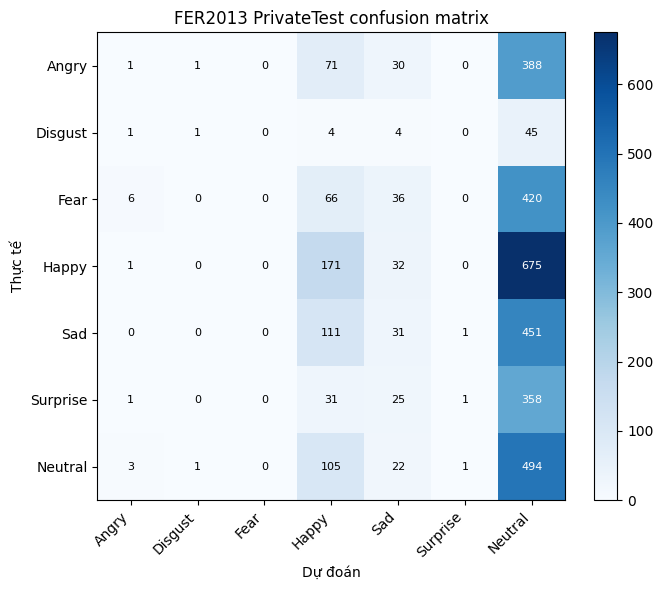

In [7]:
# Rows are true classes; columns are predicted classes
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(CLASS_NAMES)),
)
plot_confusion(
    cm=cm,
    class_names=CLASS_NAMES,
    title="FER2013 PrivateTest confusion matrix",
    path=ROOT / "exps" / "confusion_matrix.png",
)

## **3. Dự đoán dữ liệu Kaggle**

Cell tiếp theo lấy cố định 500 ảnh đầu tiên từ `kaggle_test_x.npy` để tạo submission mẫu có đúng 500 dòng. Vì Kaggle test không có nhãn, `placeholder_y` chỉ là mảng giả để dùng chung Dataset/predict; nó không tham gia tính điểm. Kết quả được ghi vào `exps/submission.csv` với cột `emotion`.

In [8]:
# Create a deterministic 500-row sample submission
SUBMISSION_SIZE = 500
KAGGLE_TEST_PATH = ROOT / "data" / "processed" / "kaggle_test_x.npy"
kaggle_x = np.load(KAGGLE_TEST_PATH)

if len(kaggle_x) < SUBMISSION_SIZE:
    raise ValueError(
        f"Expected at least {SUBMISSION_SIZE} test images; found {len(kaggle_x)}"
    )
kaggle_x = kaggle_x[:SUBMISSION_SIZE]
dummy_labels = np.zeros(SUBMISSION_SIZE, dtype=np.int64)

_, kaggle_predictions = predict(
    model=model,
    x=kaggle_x,
    y=dummy_labels,
    mean=stats["mean"],
    std=stats["std"],
    device=device,
)
submission = pd.DataFrame({"emotion": kaggle_predictions})
if len(submission) != SUBMISSION_SIZE:
    raise ValueError(f"Expected 500 predictions; found {len(submission)}")

submission_path = ROOT / "exps" / "submission.csv"
submission.to_csv(submission_path, index=False)
print(f"Saved {len(submission)} predictions to {submission_path}")

Saved 500 predictions to D:\Programming\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 8 (Convolutional Neural Network)\Lab08b - Emotion Recognition\exps\submission.csv
